Atividade — Desocupação por sexo (2012 e 2026) e horas de afazeres (2022)

As Tabelas 5 trazem a composição das pessoas desocupadas: em cada estado, quanto do total sem emprego era homem e quanto era mulher. Os dois percentuais somam 100. Não é a taxa de desocupação.

A Tabela 1.1.1, a mesma da aula 2, traz as horas semanais de cuidados e afazeres domésticos em 2022. Os três arquivos ficam na mesma pasta do notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

1. Abrir as duas Tabelas 5

In [2]:
t2012 = pd.read_csv(
    "Tabela5-sem_emprego_2012.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)
t2026 = pd.read_csv(
    "Tabela5-sem_emprego_2026.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
)
t2012

,Sigla,Código,Estado,Desocupados - homens (2012 T1),Desocupados - mulheres (2012 T1)
0,AC,12,Acre,45.3,54.7
1,AL,27,Alagoas,44.7,55.3
2,AM,13,Amazonas,47.5,52.5
3,AP,16,Amapá,48.1,51.9
4,BA,29,Bahia,43.8,56.2
5,CE,23,Ceará,51.1,48.9
6,DF,53,Distrito Federal,41.0,59.0
7,ES,32,Espírito Santo,46.4,53.6
8,GO,52,Goiás,41.0,59.0
9,MA,21,Maranhão,47.2,52.8


In [3]:
t2026

,Sigla,Código,Estado,Desocupados - homens (2026 T1),Desocupados - mulheres (2026 T1)
0,AC,12,Acre,53.2,46.8
1,AL,27,Alagoas,50.7,49.3
2,AM,13,Amazonas,46.8,53.2
3,AP,16,Amapá,51.1,48.9
4,BA,29,Bahia,44.7,55.3
5,CE,23,Ceará,52.7,47.3
6,DF,53,Distrito Federal,47.9,52.1
7,ES,32,Espírito Santo,47.5,52.5
8,GO,52,Goiás,47.5,52.5
9,MA,21,Maranhão,49.1,50.9


Juntar 2012 e 2026 pela sigla, pelo código e pelo nome do estado. O `inner` só guarda o estado que existe nas duas tabelas. Aqui são os 27.

In [4]:
comp = t2012.merge(t2026, on=["Sigla", "Código", "Estado"], how="inner")
comp = comp.rename(columns={
    "Desocupados - homens (2012 T1)": "homens_2012",
    "Desocupados - mulheres (2012 T1)": "mulheres_2012",
    "Desocupados - homens (2026 T1)": "homens_2026",
    "Desocupados - mulheres (2026 T1)": "mulheres_2026",
})
comp

,Sigla,Código,Estado,homens_2012,mulheres_2012,homens_2026,mulheres_2026
0,AC,12,Acre,45.3,54.7,53.2,46.8
1,AL,27,Alagoas,44.7,55.3,50.7,49.3
2,AM,13,Amazonas,47.5,52.5,46.8,53.2
3,AP,16,Amapá,48.1,51.9,51.1,48.9
4,BA,29,Bahia,43.8,56.2,44.7,55.3
5,CE,23,Ceará,51.1,48.9,52.7,47.3
6,DF,53,Distrito Federal,41.0,59.0,47.9,52.1
7,ES,32,Espírito Santo,46.4,53.6,47.5,52.5
8,GO,52,Goiás,41.0,59.0,47.5,52.5
9,MA,21,Maranhão,47.2,52.8,49.1,50.9


Comparar ano a ano. A variação é a participação das mulheres em 2026 menos a de 2012, em pontos percentuais. Negativo significa que as mulheres passaram a ser uma fatia menor das pessoas desocupadas.

In [5]:
comp["var_mulheres"] = (comp["mulheres_2026"] - comp["mulheres_2012"]).round(1)
comparacao = comp.sort_values("var_mulheres")[
    ["Sigla", "Estado", "mulheres_2012", "mulheres_2026", "var_mulheres"]
]
comparacao

,Sigla,Estado,mulheres_2012,mulheres_2026,var_mulheres
0,AC,Acre,54.7,46.8,-7.9
6,DF,Distrito Federal,59.0,52.1,-6.9
8,GO,Goiás,59.0,52.5,-6.5
1,AL,Alagoas,55.3,49.3,-6.0
17,PR,Paraná,59.7,53.7,-6.0
10,MG,Minas Gerais,56.9,51.4,-5.5
13,PA,Pará,56.8,51.7,-5.1
15,PE,Pernambuco,56.1,51.3,-4.8
22,RS,Rio Grande do Sul,57.2,52.6,-4.6
14,PB,Paraíba,55.6,51.1,-4.5


In [6]:
caiu = comp[comp["var_mulheres"] < 0]
subiu = comp[comp["var_mulheres"] > 0]
maioria_2012 = comp[comp["mulheres_2012"] > comp["homens_2012"]]
maioria_2026 = comp[comp["mulheres_2026"] > comp["homens_2026"]]
virou_homem = comp[
    (comp["mulheres_2012"] > comp["homens_2012"])
    & (comp["mulheres_2026"] < comp["homens_2026"])
]
virou_mulher = comp[
    (comp["mulheres_2012"] < comp["homens_2012"])
    & (comp["mulheres_2026"] > comp["homens_2026"])
]

print(f"Estados em que a fatia das mulheres caiu: {len(caiu)}")
print(f"Estados em que a fatia das mulheres subiu: {len(subiu)}")
print(f"Mulheres eram maioria dos desocupados em 2012: {len(maioria_2012)} estados")
print(f"Mulheres eram maioria dos desocupados em 2026: {len(maioria_2026)} estados")
print("Deixaram de ser maioria:", ", ".join(virou_homem["Estado"]))
print("Passaram a ser maioria:", ", ".join(virou_mulher["Estado"]))

maior_queda = comp.loc[comp["var_mulheres"].idxmin()]
maior_alta = comp.loc[comp["var_mulheres"].idxmax()]
print(
    f"Maior queda: {maior_queda.Estado} ({maior_queda.mulheres_2012}% para {maior_queda.mulheres_2026}%)"
)
print(
    f"Maior alta: {maior_alta.Estado} ({maior_alta.mulheres_2012}% para {maior_alta.mulheres_2026}%)"
)

Estados em que a fatia das mulheres caiu: 20
Estados em que a fatia das mulheres subiu: 7
Mulheres eram maioria dos desocupados em 2012: 23 estados
Mulheres eram maioria dos desocupados em 2026: 22 estados
Deixaram de ser maioria: Acre, Alagoas, Amapá
Passaram a ser maioria: Rio Grande do Norte, Tocantins
Maior queda: Acre (54.7% para 46.8%)
Maior alta: Rondônia (56.6% para 67.0%)


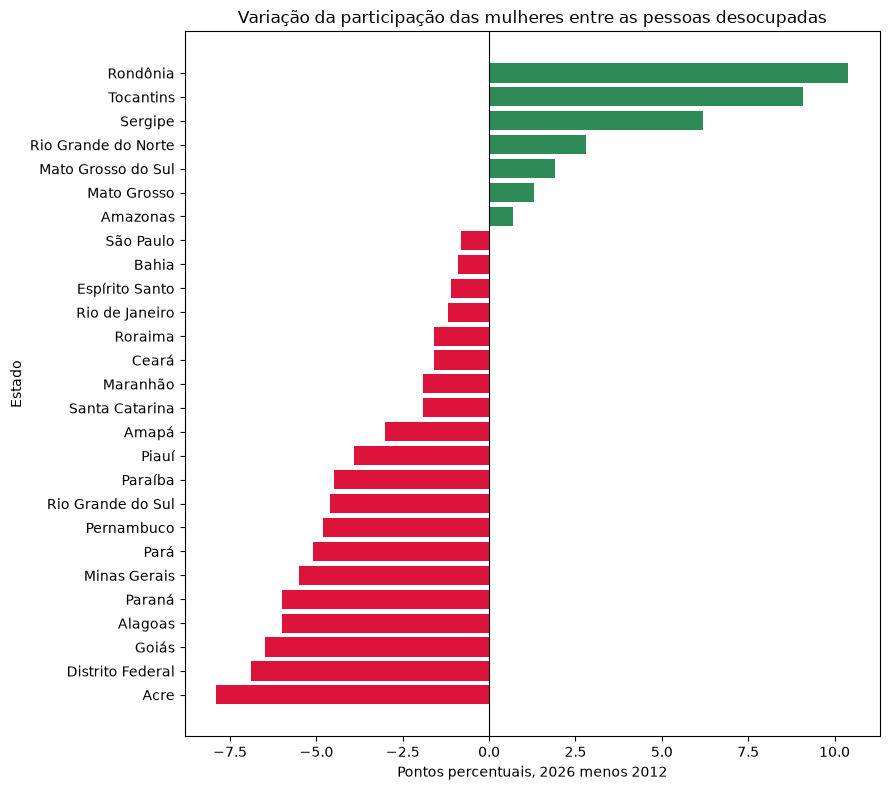

In [7]:
ordem = comp.sort_values("var_mulheres")
fig, ax = plt.subplots(figsize=(9, 8))
cores = ["crimson" if v < 0 else "seagreen" for v in ordem["var_mulheres"]]
ax.barh(ordem["Estado"], ordem["var_mulheres"], color=cores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Variação da participação das mulheres entre as pessoas desocupadas")
ax.set_xlabel("Pontos percentuais, 2026 menos 2012")
ax.set_ylabel("Estado")
fig.tight_layout()
plt.show()

A participação das mulheres entre as pessoas desocupadas caiu em 20 estados e subiu em 7. A maior queda foi no Acre, de 54,7% para 46,8%. A maior alta foi em Rondônia, de 56,6% para 67,0%, seguida de Tocantins (44,7% para 53,8%) e Sergipe (53,5% para 59,7%).

Em 2012 as mulheres eram maioria das pessoas desocupadas em 23 estados. Em 2026, em 22. Acre, Alagoas e Amapá deixaram de ter maioria feminina. Rio Grande do Norte e Tocantins passaram a ter. Ceará e Piauí continuaram com maioria masculina nos dois anos.

Abrir a Tabela 1.1.1 da aula 2, aba de 2022. As linhas 0 a 7 são título e cabeçalho. Os dados vão da linha 8 (Brasil) até a linha 40 (Distrito Federal). As abas com CV são coeficiente de variação e ficam de fora.

In [8]:
bruto = pd.read_excel("Tabela 1.1.1.xls", sheet_name="2022", header=None)
indicador_1 = bruto.iloc[8:41].copy()
indicador_1.columns = [
    "uf_regiao",
    "total",
    "total_branca",
    "total_preta_parda",
    "homem_branca",
    "homem_preta_parda",
    "mulher_branca",
    "mulher_preta_parda",
]
indicador_1 = indicador_1.reset_index(drop=True)
for col in indicador_1.columns[1:]:
    indicador_1[col] = pd.to_numeric(indicador_1[col], errors="coerce")

indicador_1["horas_homem"] = (
    (indicador_1["homem_branca"] + indicador_1["homem_preta_parda"]) / 2
).round(2)
indicador_1["horas_mulher"] = (
    (indicador_1["mulher_branca"] + indicador_1["mulher_preta_parda"]) / 2
).round(2)
indicador_1

/tmp/ipykernel_16764/1097885080.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  bruto = pd.read_excel("Tabela 1.1.1.xls", sheet_name="2022", header=None)


,uf_regiao,total,total_branca,total_preta_parda,homem_branca,homem_preta_parda,mulher_branca,mulher_preta_parda,horas_homem,horas_mulher
0,Brasil,16.985781,16.545930,17.333142,11.705136,11.746330,20.404106,22.037998,11.73,21.22
1,Norte,16.187037,15.925246,16.256032,11.588653,11.514646,19.295780,20.534188,11.55,19.91
2,Rondônia,17.014162,16.727733,17.101523,12.111127,12.544080,20.412887,21.061410,12.33,20.74
3,Acre,13.606903,13.806929,13.541399,10.796120,9.686983,16.130352,16.710754,10.24,16.42
4,Amazonas,16.807290,15.987545,16.995493,12.233043,12.822584,18.764969,20.716986,12.53,19.74
5,Roraima,13.639257,13.651755,13.633606,10.814803,10.476601,16.135877,16.560244,10.65,16.35
6,Pará,16.474268,16.181627,16.560239,11.524306,11.026707,19.835110,21.591144,11.28,20.71
7,Amapá,13.586656,14.389180,13.415091,11.116821,10.749444,16.648579,15.908487,10.93,16.28
8,Tocantins,15.815781,15.701788,15.768728,10.733863,11.682616,19.663713,19.629399,11.21,19.65
9,Nordeste,18.499396,18.151700,18.610911,11.723907,11.848436,22.744666,23.716716,11.79,23.23


Cruzar com a tabela da desocupação pelo nome do estado. Brasil e as grandes regiões não estão nas Tabelas 5, então não entram nesse resultado. `horas_homem` e `horas_mulher` são a média simples dos grupos branca e preta ou parda, como na aula 2.

In [9]:
cruzado = comp.merge(
    indicador_1,
    how="left",
    left_on="Estado",
    right_on="uf_regiao",
)
cruzado = cruzado.drop(columns=["uf_regiao"])
print("Estados sem par na Tabela 1.1.1:", cruzado["total"].isna().sum())
cruzado[
    [
        "Sigla",
        "Estado",
        "mulheres_2012",
        "mulheres_2026",
        "var_mulheres",
        "horas_mulher",
        "horas_homem",
    ]
].sort_values("horas_mulher", ascending=False)

Estados sem par na Tabela 1.1.1: 0


,Sigla,Estado,mulheres_2012,mulheres_2026,var_mulheres,horas_mulher,horas_homem
1,AL,Alagoas,55.3,49.3,-6.0,24.98,12.74
5,CE,Ceará,48.9,47.3,-1.6,23.99,12.50
19,RN,Rio Grande do Norte,49.0,51.8,2.8,23.98,11.13
14,PB,Paraíba,55.6,51.1,-4.5,23.84,12.44
15,PE,Pernambuco,56.1,51.3,-4.8,23.80,12.59
24,SE,Sergipe,53.5,59.7,6.2,23.69,11.05
4,BA,Bahia,56.2,55.3,-0.9,22.89,10.77
10,MG,Minas Gerais,56.9,51.4,-5.5,22.63,11.47
16,PI,Piauí,48.8,44.9,-3.9,22.09,11.73
7,ES,Espírito Santo,53.6,52.5,-1.1,21.33,11.91


O cruzamento fecha nos 27 estados.

Em todos eles as mulheres dedicam mais horas semanais a cuidados e afazeres do que os homens. A diferença vai de cerca de 16 horas (Amapá, Roraima e Acre) a cerca de 25 horas (Alagoas).

Essa ordem não acompanha a composição da desocupação. Alagoas tem a maior carga de afazeres das mulheres e, mesmo assim, a fatia delas entre as pessoas desocupadas caiu de 55,3% para 49,3%. Rondônia tem a maior fatia feminina em 2026 (67,0%) com cerca de 21 horas, longe de ser o estado em que as mulheres mais trabalham em casa. As duas medidas falam de coisas diferentes: uma é o tempo de trabalho doméstico em 2022, a outra é quem compõe o grupo sem emprego em 2012 e em 2026.